<a href="https://colab.research.google.com/github/LeuRNburgJoe11/DSA4213_Assignment/blob/main/Part1_models_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA4213 Assignment 1 — Part I: Language Model Comparison (Colab version)

**Attribution:** n-gram LM and tokenizer adapted from the DSA4213 Lecture 1 notebook; RNN, LSTM and Transformer LMs adapted from the DSA4213 Lecture 3 notebook.

**Before running:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

What changed from the local notebook:
- Cell 0 mounts Google Drive so data, checkpoints and results survive Colab disconnects.
- Data is read from `data/processed/` on Drive if present, otherwise downloaded from Hugging Face (`wikitext-2-raw-v1`, public — **no API token needed**).
- WikiText `@-@`, `@,@`, `@.@` markers are cleaned before tokenizing.
- The n-gram model now uses **the same token stream and 30k vocabulary (with `<unk>`)** as the neural models, so perplexities are comparable.
- One shared `train_model()` for RNN / LSTM / Transformer, logging per-epoch loss, wall-clock time, parameter count and inference throughput.
- Mixed precision (AMP) on GPU, checkpoints saved every epoch, a loss-curve plot and a matched-decoding generation cell at the end.

In [ ]:
# ==========================================
# CELL 0: COLAB SETUP (Drive + GPU check)
# ==========================================
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/dsa4213/ind_assignment")   # change if your folder differs
else:
    PROJECT_DIR = Path.cwd()

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working directory:", Path.cwd())

import torch
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU — in Colab use Runtime > Change runtime type > T4 GPU")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/drive/MyDrive/dsa4213/ind_assignment
GPU: Tesla T4


In [ ]:
# ==========================================
# CELL 1: DATA — use data/processed/ if present, else download WikiText-2
# ==========================================
# DATA_SOURCE: "auto"  -> use existing data/processed/*.txt, otherwise download
#              "hf"    -> always (re)download wikitext-2-raw-v1 and overwrite
DATA_SOURCE = "auto"

results_path = Path("results"); results_path.mkdir(exist_ok=True)
data_dir = Path("data/processed"); data_dir.mkdir(parents=True, exist_ok=True)
train_path, valid_path, test_path = (data_dir / f"{s}.txt" for s in ("train", "valid", "test"))

have_local = all(p.exists() for p in (train_path, valid_path, test_path))
if DATA_SOURCE == "hf" or not have_local:
    try:
        from datasets import load_dataset
    except ImportError:
        !pip -q install datasets
        from datasets import load_dataset
    # Public dataset: no Hugging Face token required. (Colab may print an
    # "HF_TOKEN not found" warning — it is safe to ignore.)
    ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
    for split, path in (("train", train_path), ("validation", valid_path), ("test", test_path)):
        path.write_text("".join(ds[split]["text"]), encoding="utf-8")
    print("Downloaded wikitext-2-raw-v1 from Hugging Face into data/processed/")
else:
    print("Using existing files in data/processed/")

for p in (train_path, valid_path, test_path):
    print(f"{p.name:10s} {p.stat().st_size/1e6:6.2f} MB")

Using existing files in data/processed/
train.txt   10.91 MB
valid.txt    1.14 MB
test.txt     1.29 MB


In [ ]:
# ==========================================
# CELL 2: SHARED UTILITIES & TOKENIZER (used by ALL models)
# ==========================================
import re, math, json, time, copy, random
from collections import Counter, defaultdict
import numpy as np

START_TOKEN, END_TOKEN = "<s>", "</s>"
PAD_TOKEN, UNK_TOKEN = "<pad>", "<unk>"

TOKEN_PATTERN = re.compile(r"\w+(?:'\w+)?|[^\w\s]")
WIKITEXT_MARKERS = re.compile(r" @([-,.])@ ")   # " @-@ " -> "-", " @,@ " -> ",", " @.@ " -> "."

def clean_wikitext(line):
    """Undo WikiText's @x@ escaping so e.g. '1 @,@ 000' becomes '1,000'.
    Otherwise each marker becomes 3 near-deterministic tokens that
    artificially lower every model's perplexity."""
    return WIKITEXT_MARKERS.sub(r"\1", line)

def tokenize(text):
    normalized = clean_wikitext(text).lower().replace("’", "'")
    return TOKEN_PATTERN.findall(normalized)

def read_tokens(path):
    """One continuous token stream; each non-empty line wrapped in <s> ... </s>."""
    tokens = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        line_tokens = tokenize(line.strip())
        if line_tokens:
            tokens.extend([START_TOKEN, *line_tokens, END_TOKEN])
    return tokens

def build_vocabulary(tokens, max_vocab_size=30000):
    counts = Counter(tokens)
    most_common = [t for t, _ in counts.most_common(max_vocab_size)]
    vocabulary = [PAD_TOKEN, UNK_TOKEN] + sorted(set(most_common) - {PAD_TOKEN, UNK_TOKEN})
    return {t: i for i, t in enumerate(vocabulary)}, vocabulary

def map_to_vocab(tokens, token_to_id):
    return [t if t in token_to_id else UNK_TOKEN for t in tokens]

def compute_perplexity(avg_cross_entropy_bits):
    return 2 ** avg_cross_entropy_bits

MAX_VOCAB_SIZE = 30000
train_tokens = read_tokens(train_path)
valid_tokens = read_tokens(valid_path)
test_tokens  = read_tokens(test_path)
token_to_id, vocabulary = build_vocabulary(train_tokens, MAX_VOCAB_SIZE)

n_unk = sum(t not in token_to_id for t in train_tokens)
print(f"Train tokens: {len(train_tokens):,} | valid: {len(valid_tokens):,} | test: {len(test_tokens):,}")
print(f"Unique train types: {len(set(train_tokens)):,} | vocab (incl. pad/unk): {len(vocabulary):,}")
print(f"Train tokens mapped to <unk>: {n_unk:,} ({n_unk/len(train_tokens):.2%})")
print("Remaining '@' tokens in train:", sum(t == "@" for t in train_tokens))

Train tokens: 2,124,061 | valid: 221,501 | test: 249,435
Unique train types: 65,992 | vocab (incl. pad/unk): 30,002
Train tokens mapped to <unk>: 45,140 (2.13%)
Remaining '@' tokens in train: 8


In [ ]:
# ==========================================
# CELL 3: N-GRAM LANGUAGE MODEL (same token stream + vocab as neural models)
# ==========================================
class CountLanguageModel:
    """Interpolated add-k n-gram LM over a continuous token stream.
    Predicts every token after the first, exactly like the neural models."""
    def __init__(self, max_order):
        self.max_order = max_order
        self.next_counts = {o: defaultdict(Counter) for o in range(1, max_order + 1)}
        self.history_counts = {o: Counter() for o in range(1, max_order + 1)}
        self.vocab_size = 0

    def fit(self, tokens, vocab_size):
        self.vocab_size = vocab_size
        for order in range(1, self.max_order + 1):
            nc, hc = self.next_counts[order], self.history_counts[order]
            for pos in range(order - 1, len(tokens)):
                history = tuple(tokens[pos - order + 1: pos])
                nc[history][tokens[pos]] += 1
                hc[history] += 1
        return self

    def probability(self, history, word, order, add_k):
        h = tuple(history[len(history) - (order - 1):]) if order > 1 else ()
        num = self.next_counts[order][h][word] + add_k if h in self.next_counts[order] else add_k
        den = self.history_counts[order][h] + add_k * self.vocab_size
        return num / den if den > 0 else 0.0

    def interpolated_probability(self, history, word, weights, add_k):
        return sum(w * self.probability(history, word, o, add_k) for o, w in weights.items())

def evaluate_ngram_model(model, tokens, weights, add_k):
    n = model.max_order
    log_prob_sum, count = 0.0, 0
    for pos in range(1, len(tokens)):
        history = tokens[max(0, pos - n + 1): pos]
        p = model.interpolated_probability(history, tokens[pos], weights, add_k)
        log_prob_sum += math.log2(max(p, 1e-12))
        count += 1
    ce = -log_prob_sum / count
    return ce, 2 ** ce

In [ ]:
# ==========================================
# CELL 4: TRAIN & EVALUATE N-GRAM MODEL
# ==========================================
ng_train = map_to_vocab(train_tokens, token_to_id)
ng_valid = map_to_vocab(valid_tokens, token_to_id)
ng_test  = map_to_vocab(test_tokens,  token_to_id)
ngram_vocab_size = len(vocabulary) - 1          # exclude <pad>, which is never predicted

max_order = 3
t0 = time.perf_counter()
ngram_model = CountLanguageModel(max_order).fit(ng_train, ngram_vocab_size)
ngram_fit_time = time.perf_counter() - t0
weights = {o: 1.0 / max_order for o in range(1, max_order + 1)}

print("--- Tuning add_k on dev set ---")
best_k, best_dev_pp = None, float("inf")
for k in [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]:
    _, dev_pp = evaluate_ngram_model(ngram_model, ng_valid, weights, k)
    print(f"add_k = {k:<5} | dev PPL: {dev_pp:.2f}")
    if dev_pp < best_dev_pp:
        best_k, best_dev_pp = k, dev_pp

t0 = time.perf_counter()
test_ce, test_pp = evaluate_ngram_model(ngram_model, ng_test, weights, best_k)
ngram_eval_time = time.perf_counter() - t0

n_ngram_entries = sum(sum(len(c) for c in ngram_model.next_counts[o].values()) for o in range(1, max_order + 1))
ngram_result = {
    "model": "trigram", "test_ce_bits": test_ce, "test_ppl": test_pp, "best_valid_ppl": best_dev_pp,
    "params": n_ngram_entries, "train_time_s": ngram_fit_time,
    "infer_tokens_per_s": (len(ng_test) - 1) / ngram_eval_time, "device": "cpu", "add_k": best_k,
}
print(f"\nBest add_k: {best_k} | test CE: {test_ce:.4f} bits/token | test PPL: {test_pp:.2f}")
print(f"Stored n-gram entries: {n_ngram_entries:,} | fit time: {ngram_fit_time:.1f}s")

--- Tuning add_k on dev set ---
add_k = 0.001 | dev PPL: 299.67
add_k = 0.01  | dev PPL: 386.95
add_k = 0.05  | dev PPL: 502.77
add_k = 0.1   | dev PPL: 568.87
add_k = 0.5   | dev PPL: 763.78
add_k = 1.0   | dev PPL: 869.60

Best add_k: 0.001 | test CE: 8.1523 bits/token | test PPL: 284.50
Stored n-gram entries: 2,009,444 | fit time: 9.1s


In [ ]:
# ==========================================
# CELL 5: NEURAL MODELS (RNN, LSTM, TRANSFORMER) + DATA LOADERS
# ==========================================
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class VanillaRNNLM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)
    def forward(self, x, hidden=None):
        out, hidden = self.rnn(self.embedding(x), hidden)
        return self.fc(out), hidden

class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers=1, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_dim, vocab_size)
    def forward(self, x, hidden=None):
        out, hidden = self.lstm(self.embedding(x), hidden)
        return self.fc(out), hidden

class PositionalEncoding(nn.Module):
    def __init__(self, embed_dim, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, embed_dim)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, embed_dim, 2).float() * (-math.log(10000.0) / embed_dim))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class TransformerLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, nhead, hidden_dim, num_layers, dropout=0.1):
        super().__init__()
        self.embed_dim = embed_dim
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.pos_encoder = PositionalEncoding(embed_dim)
        layer = nn.TransformerEncoderLayer(embed_dim, nhead, hidden_dim, dropout, batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.fc = nn.Linear(embed_dim, vocab_size)
    def forward(self, x, hidden=None):
        x = self.pos_encoder(self.embedding(x) * math.sqrt(self.embed_dim))
        mask = nn.Transformer.generate_square_subsequent_mask(x.size(1), device=x.device)
        out = self.transformer(x, mask=mask, is_causal=True)
        return self.fc(out), None

def make_data_loader(tokens, token_to_id, sequence_length, batch_size, shuffle):
    unk = token_to_id[UNK_TOKEN]
    ids = torch.tensor([token_to_id.get(t, unk) for t in tokens], dtype=torch.long)
    n = (len(ids) - 1) // sequence_length
    inputs  = ids[: n * sequence_length].view(n, sequence_length)
    targets = ids[1: n * sequence_length + 1].view(n, sequence_length)
    return DataLoader(TensorDataset(inputs, targets), batch_size=batch_size, shuffle=shuffle,
                      pin_memory=torch.cuda.is_available())

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"      # mixed precision: ~2x faster on a T4
print("device:", device, "| AMP:", USE_AMP)

device: cuda | AMP: True


In [ ]:
# ==========================================
# CELL 6: ONE SHARED TRAIN / EVALUATE LOOP (timing + loss history)
# ==========================================
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def evaluate_neural_model(model, loader, criterion):
    """Returns (cross-entropy bits/token, perplexity, tokens/sec)."""
    model.eval()
    total_loss, total_tokens = 0.0, 0
    sync(); t0 = time.perf_counter()
    for inputs, targets in loader:
        inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
            logits, _ = model(inputs)
        loss = criterion(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
        total_loss += loss.item()
        total_tokens += (targets != criterion.ignore_index).sum().item()
    sync(); elapsed = time.perf_counter() - t0
    bits = total_loss / total_tokens / math.log(2)
    return bits, compute_perplexity(bits), total_tokens / elapsed

def train_model(name, model, cfg, train_loader, valid_loader, criterion):
    """Shared by all neural LMs so the comparison is fair. Saves a checkpoint and
    a JSON history every epoch (to Drive), so a Colab disconnect loses little."""
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg["learning_rate"])
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history = {"epoch": [], "train_bits": [], "valid_bits": [], "valid_ppl": [], "epoch_time_s": []}
    best_valid_ppl, best_state, bad_epochs = float("inf"), None, 0

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        total_loss, total_tokens = 0.0, 0
        sync(); t0 = time.perf_counter()
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device, non_blocking=True), targets.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device.type, dtype=torch.float16, enabled=USE_AMP):
                logits, _ = model(inputs)
            loss = criterion(logits.float().reshape(-1, logits.size(-1)), targets.reshape(-1))
            n_tok = targets.numel()
            scaler.scale(loss / n_tok).backward()        # mean loss for stable gradients
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer); scaler.update()
            total_loss += loss.item(); total_tokens += n_tok
        sync(); epoch_time = time.perf_counter() - t0

        train_bits = total_loss / total_tokens / math.log(2)
        valid_bits, valid_ppl, _ = evaluate_neural_model(model, valid_loader, criterion)
        for k, v in zip(history, (epoch, train_bits, valid_bits, valid_ppl, epoch_time)):
            history[k].append(v)
        print(f"[{name}] epoch {epoch:02d} | train CE {train_bits:.3f} bits | valid CE {valid_bits:.3f} bits "
              f"| valid PPL {valid_ppl:8.2f} | {epoch_time:6.1f}s")

        if valid_ppl < best_valid_ppl:
            best_valid_ppl, bad_epochs = valid_ppl, 0
            best_state = copy.deepcopy(model.state_dict())
            torch.save({"model_state_dict": best_state, "token_to_id": token_to_id,
                        "vocabulary": vocabulary, "config": cfg}, results_path / f"{name}.pt")
        else:
            bad_epochs += 1
        (results_path / f"history_{name}.json").write_text(json.dumps(history, indent=1))
        if bad_epochs >= cfg["patience"]:
            print(f"[{name}] early stopping after epoch {epoch}")
            break

    model.load_state_dict(best_state)
    return best_valid_ppl, history

def run_experiment(name, model, cfg):
    set_seed(cfg["seed"])
    train_loader = make_data_loader(train_tokens, token_to_id, cfg["sequence_length"], cfg["batch_size"], True)
    valid_loader = make_data_loader(valid_tokens, token_to_id, cfg["sequence_length"], cfg["batch_size"], False)
    test_loader  = make_data_loader(test_tokens,  token_to_id, cfg["sequence_length"], cfg["batch_size"], False)
    criterion = nn.CrossEntropyLoss(ignore_index=token_to_id[PAD_TOKEN], reduction="sum")

    print(f"\n=== {name}: {count_params(model):,} parameters ===")
    best_valid_ppl, history = train_model(name, model, cfg, train_loader, valid_loader, criterion)
    test_bits, test_ppl, tok_per_s = evaluate_neural_model(model, test_loader, criterion)
    result = {
        "model": name, "test_ce_bits": test_bits, "test_ppl": test_ppl, "best_valid_ppl": best_valid_ppl,
        "params": count_params(model), "train_time_s": sum(history["epoch_time_s"]),
        "epochs_run": len(history["epoch"]), "infer_tokens_per_s": tok_per_s,
        "device": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    }
    print(f"[{name}] TEST CE {test_bits:.4f} bits/token | TEST PPL {test_ppl:.2f} | "
          f"{tok_per_s:,.0f} tokens/s inference")
    (results_path / f"result_{name}.json").write_text(json.dumps(result, indent=1))
    return result

# Shared hyperparameters — identical for all three neural models (fair comparison)
BASE_CFG = dict(epochs=15, batch_size=64, sequence_length=32, embed_dim=128, hidden_dim=256,
                learning_rate=1e-3, patience=2, seed=42)
all_results = [ngram_result]

In [ ]:
# ==========================================
# CELL 7: RNN
# ==========================================
rnn_cfg = dict(BASE_CFG)
set_seed(rnn_cfg["seed"])
rnn_model = VanillaRNNLM(len(vocabulary), rnn_cfg["embed_dim"], rnn_cfg["hidden_dim"])
all_results.append(run_experiment("rnn", rnn_model, rnn_cfg))


=== rnn: 11,649,586 parameters ===
[rnn] epoch 01 | train CE 8.904 bits | valid CE 8.089 bits | valid PPL   272.30 |   27.6s
[rnn] epoch 02 | train CE 7.870 bits | valid CE 7.814 bits | valid PPL   224.96 |   26.0s
[rnn] epoch 03 | train CE 7.408 bits | valid CE 7.714 bits | valid PPL   209.95 |   26.2s
[rnn] epoch 04 | train CE 7.088 bits | valid CE 7.665 bits | valid PPL   202.93 |   26.4s
[rnn] epoch 05 | train CE 6.841 bits | valid CE 7.665 bits | valid PPL   202.97 |   26.7s
[rnn] epoch 06 | train CE 6.638 bits | valid CE 7.684 bits | valid PPL   205.59 |   26.6s
[rnn] early stopping after epoch 6
[rnn] TEST CE 7.5764 bits/token | TEST PPL 190.87 | 185,238 tokens/s inference


In [ ]:
# ==========================================
# CELL 8: LSTM
# ==========================================
lstm_cfg = dict(BASE_CFG)
set_seed(lstm_cfg["seed"])
lstm_model = LSTMLanguageModel(len(vocabulary), lstm_cfg["embed_dim"], lstm_cfg["hidden_dim"])
all_results.append(run_experiment("lstm", lstm_model, lstm_cfg))


=== lstm: 11,946,034 parameters ===
[lstm] epoch 01 | train CE 9.160 bits | valid CE 8.281 bits | valid PPL   310.97 |   28.0s
[lstm] epoch 02 | train CE 8.153 bits | valid CE 7.950 bits | valid PPL   247.27 |   28.1s
[lstm] epoch 03 | train CE 7.740 bits | valid CE 7.782 bits | valid PPL   220.16 |   28.2s
[lstm] epoch 04 | train CE 7.438 bits | valid CE 7.680 bits | valid PPL   205.10 |   28.0s
[lstm] epoch 05 | train CE 7.190 bits | valid CE 7.632 bits | valid PPL   198.32 |   28.0s
[lstm] epoch 06 | train CE 6.979 bits | valid CE 7.607 bits | valid PPL   194.95 |   28.0s
[lstm] epoch 07 | train CE 6.796 bits | valid CE 7.603 bits | valid PPL   194.40 |   27.9s
[lstm] epoch 08 | train CE 6.634 bits | valid CE 7.612 bits | valid PPL   195.70 |   27.9s
[lstm] epoch 09 | train CE 6.490 bits | valid CE 7.624 bits | valid PPL   197.24 |   27.8s
[lstm] early stopping after epoch 9
[lstm] TEST CE 7.5140 bits/token | TEST PPL 182.79 | 188,199 tokens/s inference


In [ ]:
# ==========================================
# CELL 9: TRANSFORMER
# ==========================================
tx_cfg = dict(BASE_CFG, nhead=4, num_layers=2)   # hidden_dim = feed-forward size
set_seed(tx_cfg["seed"])
tx_model = TransformerLanguageModel(len(vocabulary), tx_cfg["embed_dim"], tx_cfg["nhead"],
                                    tx_cfg["hidden_dim"], tx_cfg["num_layers"])
all_results.append(run_experiment("transformer", tx_model, tx_cfg))


=== transformer: 7,975,474 parameters ===
[transformer] epoch 01 | train CE 8.937 bits | valid CE 8.210 bits | valid PPL   296.16 |   24.6s
[transformer] epoch 02 | train CE 8.098 bits | valid CE 7.970 bits | valid PPL   250.72 |   24.5s
[transformer] epoch 03 | train CE 7.736 bits | valid CE 7.872 bits | valid PPL   234.33 |   24.6s
[transformer] epoch 04 | train CE 7.489 bits | valid CE 7.815 bits | valid PPL   225.11 |   24.5s
[transformer] epoch 05 | train CE 7.305 bits | valid CE 7.794 bits | valid PPL   221.98 |   24.6s
[transformer] epoch 06 | train CE 7.160 bits | valid CE 7.780 bits | valid PPL   219.76 |   24.6s
[transformer] epoch 07 | train CE 7.044 bits | valid CE 7.768 bits | valid PPL   217.92 |   24.5s
[transformer] epoch 08 | train CE 6.946 bits | valid CE 7.771 bits | valid PPL   218.50 |   24.6s
[transformer] epoch 09 | train CE 6.861 bits | valid CE 7.759 bits | valid PPL   216.66 |   24.4s
[transformer] epoch 10 | train CE 6.788 bits | valid CE 7.769 bits | valid 

In [ ]:
# ==========================================
# CELL 10: RESULTS TABLE (-> results/metrics_part1.csv)
# ==========================================
import pandas as pd
df = pd.DataFrame(all_results)[["model", "test_ppl", "test_ce_bits", "best_valid_ppl", "params",
                                "train_time_s", "infer_tokens_per_s", "device"]]
df.to_csv(results_path / "metrics_part1.csv", index=False)
df.round(2)

,model,test_ppl,test_ce_bits,best_valid_ppl,params,train_time_s,infer_tokens_per_s,device
0,trigram,284.50,8.15,299.67,2009444,9.08,247502.05,cpu
1,rnn,190.87,7.58,202.93,11649586,159.44,185237.70,Tesla T4
2,lstm,182.79,7.51,194.40,11946034,251.85,188198.66,Tesla T4
3,transformer,200.87,7.65,216.66,7975474,269.94,215073.56,Tesla T4


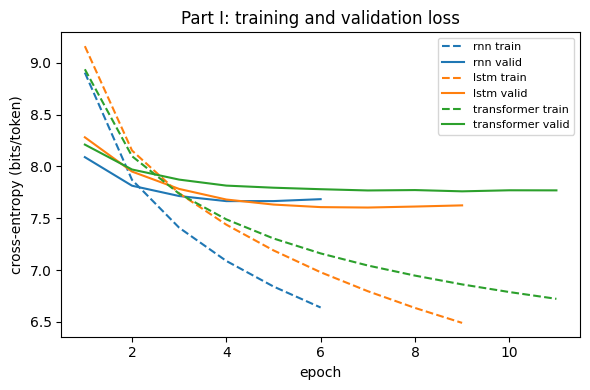

In [ ]:
# ==========================================
# CELL 11: LOSS CURVES (one figure, all neural models)
# ==========================================
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 4))
colors = {"rnn": "tab:blue", "lstm": "tab:orange", "transformer": "tab:green"}
for name, c in colors.items():
    h = json.loads((results_path / f"history_{name}.json").read_text())
    ax.plot(h["epoch"], h["train_bits"], "--", color=c, label=f"{name} train")
    ax.plot(h["epoch"], h["valid_bits"], "-",  color=c, label=f"{name} valid")
ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy (bits/token)")
ax.set_title("Part I: training and validation loss"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(results_path / "loss_curves_part1.png", dpi=200)
plt.show()

In [ ]:
# ==========================================
# CELL 12: GENERATION WITH MATCHED DECODING (-> results/generations.md)
# ==========================================
PROMPTS = ["the history of the city", "in 1995 , the band", "the species is found in",
           "during the war , the army", "the film was released"]
DECODE = dict(max_new_tokens=30, temperature=0.8, top_k=40, seed=123)

@torch.no_grad()
def generate(model, prompt, max_new_tokens, temperature, top_k, seed, context_len=32):
    model.eval()
    g = torch.Generator(device=device).manual_seed(seed)
    unk = token_to_id[UNK_TOKEN]
    ids = [token_to_id[START_TOKEN]] + [token_to_id.get(t, unk) for t in tokenize(prompt)]
    for _ in range(max_new_tokens):
        x = torch.tensor([ids[-context_len:]], device=device)   # same window for every model
        logits, _ = model(x)
        logits = logits[0, -1].float() / temperature
        logits[token_to_id[PAD_TOKEN]] = -float("inf")
        topv, topi = torch.topk(logits, top_k)
        nxt = topi[torch.multinomial(torch.softmax(topv, -1), 1, generator=g)].item()
        if vocabulary[nxt] == END_TOKEN:
            break
        ids.append(nxt)
    return " ".join(vocabulary[i] for i in ids[1:])

lines = [f"# Generated samples (temperature={DECODE['temperature']}, top-k={DECODE['top_k']}, "
         f"max {DECODE['max_new_tokens']} tokens, seed={DECODE['seed']})\n"]
for prompt in PROMPTS:
    lines.append(f"## Prompt: `{prompt}`\n")
    for name, m in (("RNN", rnn_model), ("LSTM", lstm_model), ("Transformer", tx_model)):
        text = generate(m, prompt, **DECODE)
        lines.append(f"- **{name}:** {text}")
        print(f"{name:12s}| {text}")
    lines.append(""); print()
(results_path / "generations.md").write_text("\n".join(lines), encoding="utf-8")
print("Saved results/generations.md")

RNN         | the history of the city of the 1st hampshires and <unk> rivers - au - war , where city were reported to the eastern end of the southern coast . the route continues to be
LSTM        | the history of the city ' s performance began in the season as an average <unk> of 6 percent of the british isles . it occurs when the main <unk> of haifa was the main
Transformer | the history of the city ' s international stature . the film director was screened annually in <unk> awards , and japan .

RNN         | in 1995 , the band ' s release to the <unk> , " a man in the game between the country ' s <unk> <unk> festival . the <unk> <unk> <unk> was built in the
LSTM        | in 1995 , the band was released as the first episode in the united states with the series awards , which peaked in the united states ( 2013 ) , and he <unk> the game
Transformer | in 1995 , the band ' s johnny and <unk> . the game , <unk> has been made him for the season , and was initially rigged in the first time 